:::{list-table}
:header-rows: 1
:align: center
:widths: 90 10
* - #
    # Fondamenti di programmazione
    # Canale A-L - Prof. M Mancini
    # AA 26-27 - Lezione 09
  - :::{image}attachment:5a837f06-202c-4c6e-9259-dd7a6dc01c97.png
    :width: 200px
    :::
:::

# RECAP:
- immagini come liste di liste di pixel
- disegnare linee orizzontali e verticali

# INTERMEZZO: Il [modulo `os`](https://www.perplexity.ai/search?q=come+usare+il+modulo+os+di+python), funzioni utili per interagire col file-system
- `os.getcwd()` torna il path della directory corrente
- `os.chdir(path)` cambia la directory corrente (**SCONSIGLIATO**)
- `os.stat(path)` torna un oggetto con le informazioni sul file/dir con gli attributi
  - st_mode, st_ino, st_dev, st_nlink, st_uid, st_gid, **st_size**, st_atime, st_mtime, st_ctime
- `os.listdir(path)` torna la lista di nomi di file/dir nella directory path
- `os.path.exists(path)` torna True se il file/directoy esiste
- `os.path.isfile(path)` torna True se il path è un file
- `os.path.abspath(path)` torna il path assoluto che corrisponde a un certo path

In [1]:
import os
help(os.path)

Help on module posixpath:

NAME
    posixpath - Common operations on Posix pathnames.

MODULE REFERENCE
    https://docs.python.org/3.12/library/posixpath.html

    The following documentation is automatically generated from the Python
    source files.  It may be incomplete, incorrect or include features that
    are considered implementation detail and may vary between Python
    implementations.  When in doubt, consult the module reference at the
    location listed above.

DESCRIPTION
    Instead of importing this module directly, import os and refer to
    this module as os.path.  The "os.path" name is an alias for this
    module on Posix systems; on other systems (e.g. Windows),
    os.path provides the same operations in a manner specific to that
    platform, and is an alias to another module (e.g. ntpath).

    Some of this can actually be useful on non-Posix systems too, e.g.
    for manipulation of the pathname component of URLs.

FUNCTIONS
    abspath(path)
        Return 

In [2]:
os.getcwd()                      # leggo in che dir mi trovo

'/Users/andrea/Documents/Uni/Didattica/Prog1/2025-26/Lezioni/lezione12'

In [3]:
## SE MI VOGLIO SPOSTARE
old_dir = os.getcwd()            # mi ricordo dov'ero
os.chdir('../..')                # salgo di due livelli
print(os.getcwd())               # stampo la dir corrente
os.chdir(old_dir)                # torno dov'ero
os.getcwd()                      # controllo di essere tornato

/Users/andrea/Documents/Uni/Didattica/Prog1/2025-26


'/Users/andrea/Documents/Uni/Didattica/Prog1/2025-26/Lezioni/lezione12'

In [4]:
info = os.stat('lezione12.py')   # torno info sul file (un oggetto)
print(info)
info.st_size                     # l'attributo st_size contiene la dimensione del file/dir

os.stat_result(st_mode=33188, st_ino=327203163, st_dev=16777231, st_nlink=1, st_uid=501, st_gid=20, st_size=21504, st_atime=1762772031, st_mtime=1762772029, st_ctime=1762772029)


21504

In [5]:
print(os.listdir('..'))           # elenco dei file e directories nella dir superiore

['lezione10', 'lezione11', 'lezione02', 'lezione05', 'lezione04', 'lezione03', '.mypy_cache', '.virtual_documents', 'lezione12', '.ipynb_checkpoints', 'lezione06', 'lezione01', 'lezione08', 'lezione09', 'lezione07']


In [6]:
os.path.isfile('lezione12.py')   # è un file?

True

In [7]:
os.path.exists('lezione12.pdf')  # il file/dir esiste?

True

## Costruzione di percorsi nel file-system
- vi consiglio di usare sempre il separatore di directory `'/'` anche se siete in Windows (che usa `'\\'`)
- directory + `'/'` + nomefile
- `'..'` indica la directory un livello più in su rispetto alla directory corrente
- `'.'` indica la directory corrente
- i percorsi che iniziano con `'/'` sono percorsi assoluti, che partono dalla dir principale del disco
- in Windows i percorsi iniziano con la lettera del disco, es. `'C:\\Users\\Andrea\\...'` ma voi usate `'C:/Users/Andrea/...'`


In [8]:
print(os.listdir('/Users'))              # elenco di file/dir nel path assoluto '/Users'
print(os.path.abspath('lezione12.pdf'))  # path assoluto del file lezione12.pdf

['.localized', 'Shared', 'andrea']
/Users/andrea/Documents/Uni/Didattica/Prog1/2025-26/Lezioni/lezione12/lezione12.pdf


### Errori generabili dall'accesso ai file
- `FileNotFoundError` se il file o directory non esiste
- `FileExistsError` se il file/dir esiste e volete crearlo
- `PermissionError` se non avete i permessi per leggere/creare il file
- `NotADirectoryError` se state usando os.listdir su un file invece che una directory

Per una lista completa vedi https://docs.python.org/3/library/exceptions.html

# Torniamo alle immagini

In [27]:
# definisco qualche tipo
Pixel   = tuple[int,int,int]     # con valori tra 0 e 255 compresi (1 byte)
Row     = list[Pixel]
Picture = list[Row]

# definiamo qualche colore
black : Pixel =   0,   0,   0    # luminosità minime
white : Pixel = 255, 255, 255    # luminosità massime
red   : Pixel = 255,   0,   0
green : Pixel =   0, 255,   0
blue  : Pixel =   0,   0, 255
cyan  : Pixel =   0, 255, 255
yellow: Pixel = 255, 255,   0
purple: Pixel = 255,   0, 255
grey  : Pixel = 128, 128, 128

## Disegnare un pixel a coordinate qualsiasi
**MA ... senza generare errori se le coordinate sono fuori dall'immagine**

In [28]:
# Opzione 1 --- controllando le posizioni
def draw_pixel(img : Picture, x : int|float, y : int|float, colore : Pixel):
    # ricavo l'altezza e larghezza dell'immagine contando righe e colonne
    A,L = len(img), len(img[0])
    x = int(round(x))       # voglio gestire anche coordinate float
    y = int(round(y))
    # cambio il pixel solo se è dentro l'immagine
    if 0 <= x < L and 0 <= y < A:
        img[y][x] = colore       # nella riga y e nella colonna x metto il colore

## E per le diagonali?

![](Bresenham.png)

Conviene scandire il cateto **più lungo** in modo che non ci siano colonne/righe senza pixel

Per calcolare la posizione (x,y) dei pixel usiamo l'equazione di una [retta passante per un punto](https://www.perplexity.ai/search/new?s=o&q=retta+passante+per+un+punto), ad esempio per l'estremo (x1,y1) del segmento
- $y = m * (x - x1) + y1$

In [29]:
# il disegno della diagonale dipende dalla direzione

def draw_line(img, x1, y1, x2, y2, colore):
    dx = x2-x1
    dy = y2-y1

    # vogliamo spostarci lungo la direzione della proiezione più lunga del segmento sugli assi
    # se |dx| > |dy| scandiamo le x e calcoliamo la y per ciascuna x in [x1 .. x2]
    if abs(dx) >= abs(dy):
        if x1 > x2 :                             # mi assicuro che x1<x2
            x1, y1, x2, y2 = x2, y2, x1, y1      # scambiando i punti se necessario
            dx *= -1
            dy *= -1
        m = dy/dx                                # calcolo il coefficiente angolare m=dy/dx 
        for x in range(x1, x2+1):                # e per ogni x in [x1 .. x2]
            # equazione della retta generica passante per x1,y1
            y = m * (x - x1) + y1                
            draw_pixel(img, x, y, colore)        # e disegno il pixel
    # altrimenti |dy| > |dx| e per ciascuna y calcoliamo la x
    else:            # semplicemente scambiando x e y nelle formule precedenti
        if y1 > y2 :                             # mi assicuro che y1<y2
            x1, y1, x2, y2 = x2, y2, x1, y1      # scambiando i punti se necessario
            dx *= -1
            dy *= -1
        m = dx/dy                                # calcolo m=dx/dy
        for y in range(y1, y2+1):                # e per ogni y in [y1 .. y2]
            x = m * (y - y1) + x1                # come prima scambiando y con x
            draw_pixel(img, x, y, colore)        # e disegno il pixel

CPU times: user 105 μs, sys: 0 ns, total: 105 μs
Wall time: 107 μs
CPU times: user 121 μs, sys: 1e+03 ns, total: 122 μs
Wall time: 123 μs
CPU times: user 64 μs, sys: 0 ns, total: 64 μs
Wall time: 65.1 μs
CPU times: user 112 μs, sys: 0 ns, total: 112 μs
Wall time: 113 μs


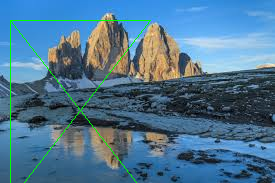

In [31]:
import images
img = images.load('3cime.png')
%time draw_line(img, 10,20, 150, 200, green)
%time draw_line(img, 10,20, 10, 200, green)
%time draw_line(img, 10,20, 150, 20, green)
%time draw_line(img, 150,20, 10, 200, green)
images.visd(img)

## Disegnare un rettangolo vuoto orizzontale
- date le coordinate dell'angolo in alto a sinistra (x1,y1)
- e di quello in basso a destra (x2,y2)

disegnamo le linee orizzontali e quelle verticali

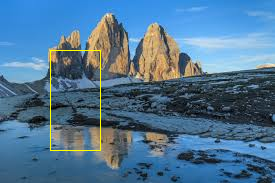

In [32]:
# NOTA: non ho controllato che i due punti siano nell'ordine giusto
def draw_empty_rectangle(img,x1,y1,x2,y2,colore):
    # dobbiamo disegnare le 4 linee
    draw_line(img, x1, y1, x2, y1, colore)
    draw_line(img, x1, y2, x2, y2, colore)
    draw_line(img, x1, y1, x1, y2, colore)
    draw_line(img, x2, y1, x2, y2, colore)

def draw_empty_rectangle2(img,x1,y1,x2,y2,colore):
    for x in range(x1, x2+1):
        draw_pixel(img, x, y1, colore)
        draw_pixel(img, x, y2, colore)
    # oppure disegnare i pixel orizzontali
    # e poi i verticali
    for y in range(y1, y2+1):
        draw_pixel(img, x1, y, colore)
        draw_pixel(img, x2, y, colore)
    
img = images.load('3cime.png')
draw_empty_rectangle(img, 50, 50, 100, 150, yellow)

images.visd(img)

## Disegnare un rettangolo pieno orizzontale
- basta campire tutta la zona con due cicli annidati

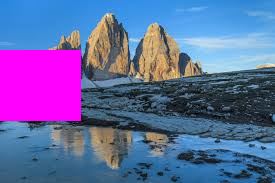

In [14]:
# questa è facile
def draw_rectangle(img, x1,y1, x2,y2, colore):
    for x in range(x1, x2+1):
        for y in range(y1, y2+1):
            draw_pixel(img, x,y, colore)

img = images.load('3cime.png')
draw_rectangle(img, -30,50, 80, 120, purple)

images.visd(img)

## E per disegnare un rettangolo vuoto ruotato?
- dati: 
  - coordinate x,y dell'angolo in alto a sinistra
  - larghezza, altezza, rotazione e colore
- convertiamo l'angolo di rotazione da gradi a radianti
- calcoliamo la posizione dei 4 angoli con un po' di trigonometria
- disegnamo le 4 linee

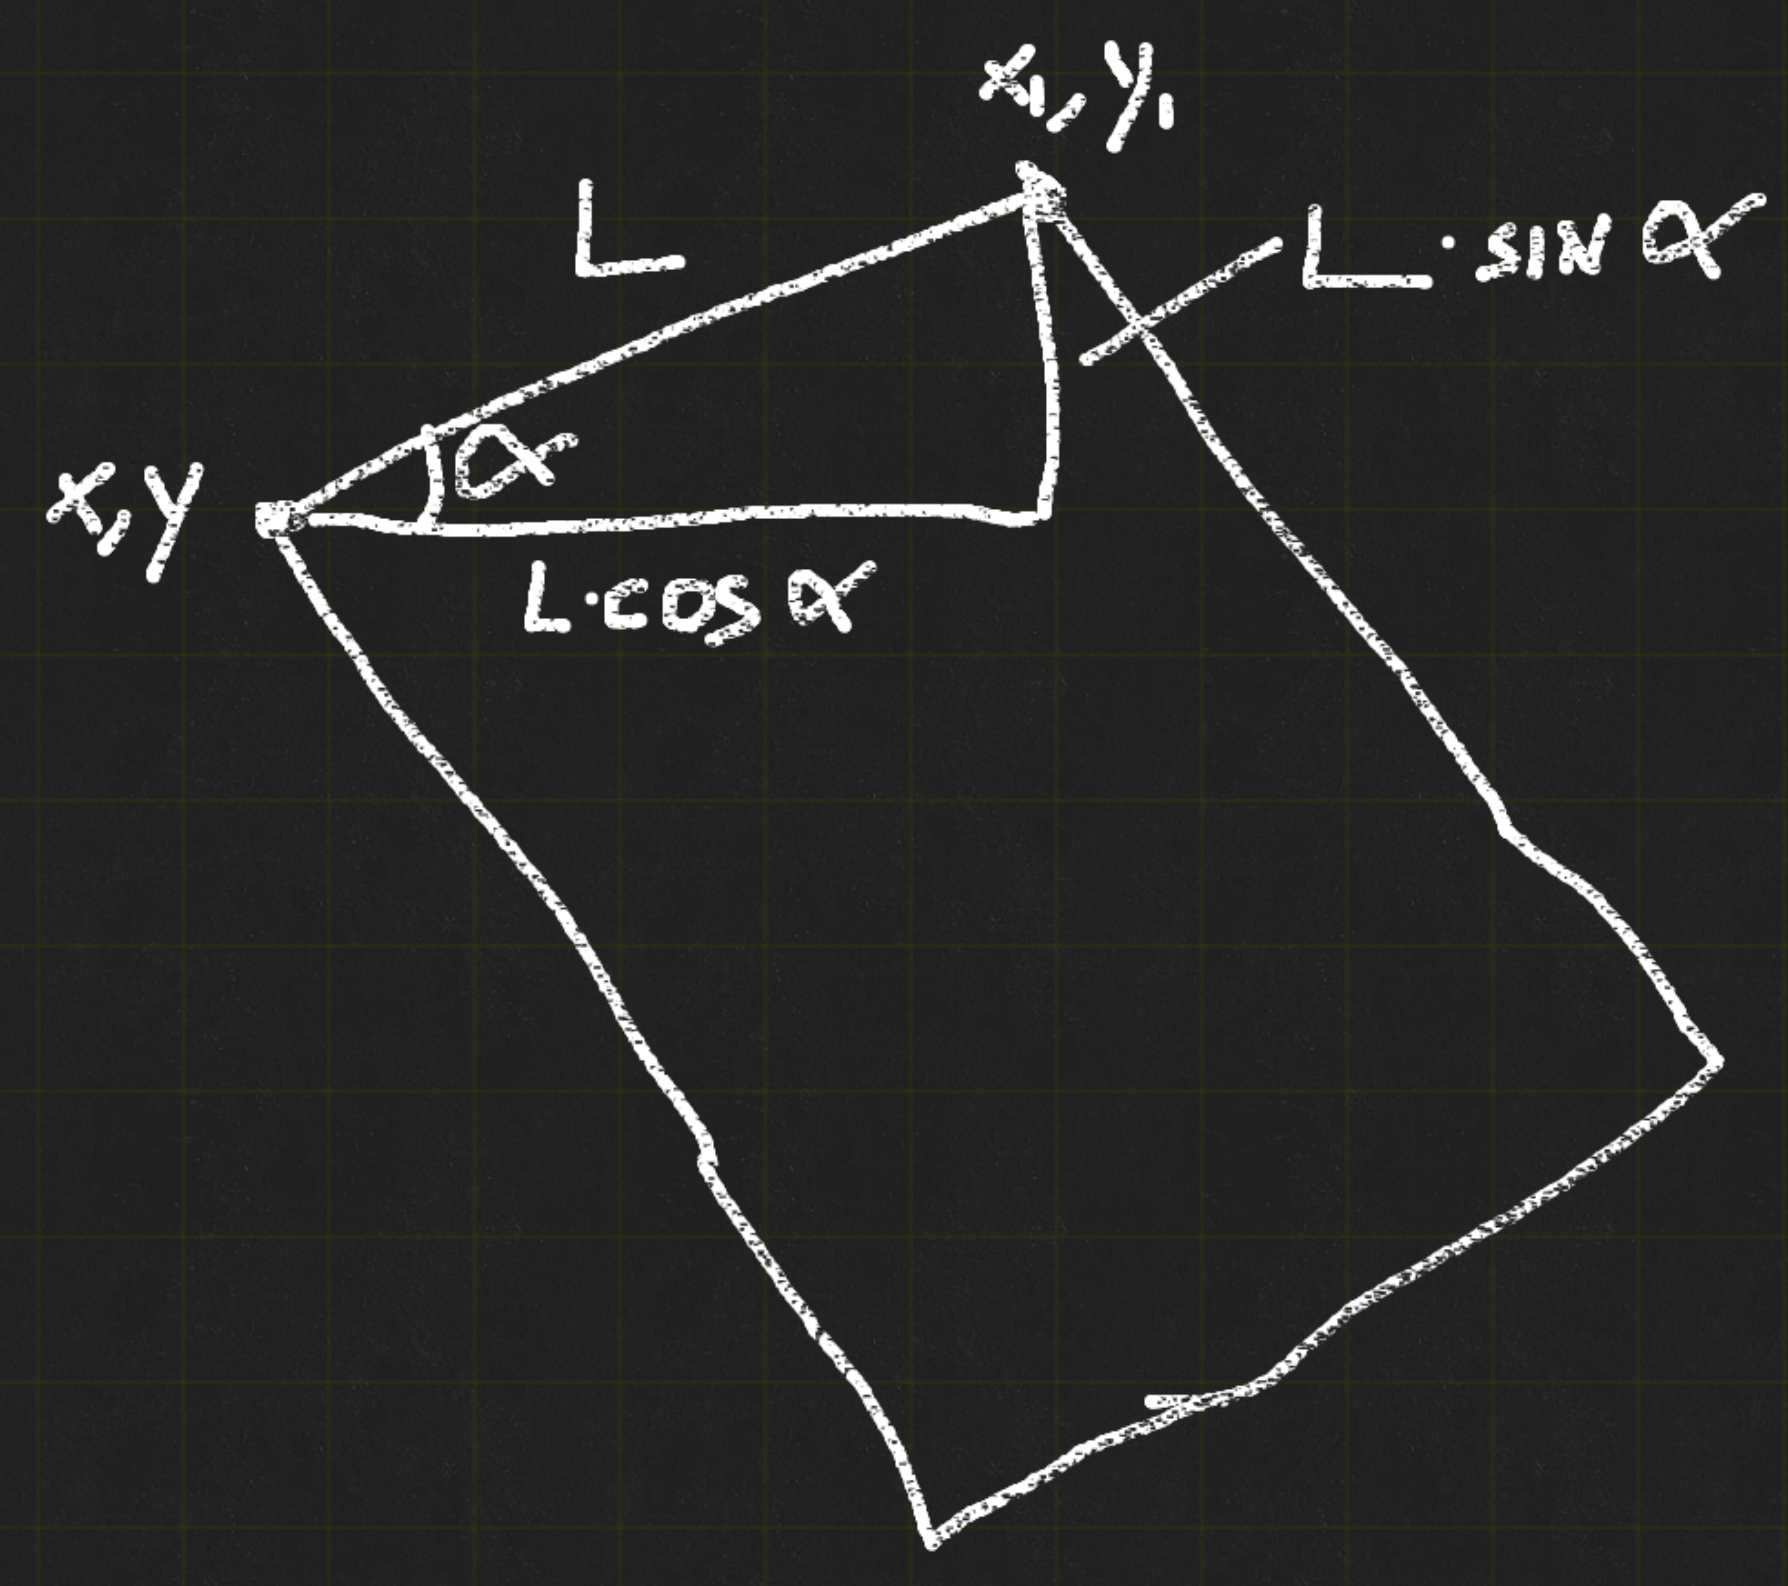

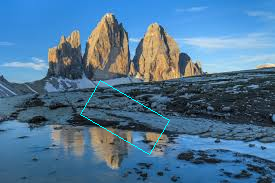

In [33]:
import math
def draw_rotated_rectangle(img, x, y, larghezza, altezza, angolo, colore):
    angolo = math.radians(angolo)
    xtr = int(x   + larghezza*math.cos(angolo))              # angolo in alto a destra
    ytr = int(y   + larghezza*math.sin(angolo))
    xbl = int(x   +   altezza*math.cos(angolo+math.pi/2))    # angolo in basso a sinistra
    ybl = int(y   +   altezza*math.sin(angolo+math.pi/2))
    xbr = int(xbl + larghezza*math.cos(angolo))              # angolo in basso a destra
    ybr = int(ybl + larghezza*math.sin(angolo))
    draw_line(img,x,  y,  xtr,ytr,colore)                    # lato superiore
    draw_line(img,x,  y,  xbl,ybl,colore)                    # lato sinistro
    draw_line(img,xtr,ytr,xbr,ybr,colore)                    # lato destro
    draw_line(img,xbl,ybl,xbr,ybr,colore)                    # lato inferiore

img = images.load('3cime.png')
draw_rotated_rectangle(img, 100, 80, 80, 40, 30, cyan)

images.visd(img)

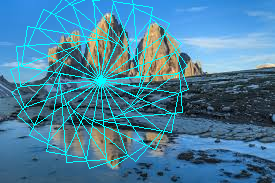

In [34]:
# E volendo mi posso divertire a disegnare tanti rettangoli ruotati
img = images.load('3cime.png')
for angolo in range(10,1000, 15):
    draw_rotated_rectangle(img, 100, 80, 80, 40, angolo, cyan)

images.visd(img)

## Disegnare una [ellisse](https://it.wikipedia.org/wiki/Ellisse)
- una ellisse ha la proprietà che: **la somma delle distanze di ogni suo punto dai due fuochi è costante**

![](Ellipse-def-e.svg.png)

### QUINDI: i punti INTERNI hanno somma delle distanze MINORE di $D=2a$

Per colorare una ellisse PIENA:
- scandiamo tutti i punti X,Y della immagine
  - calcoliamo le due distanze del punto X,Y dai due fuochi
  - se la somma è minore di $D$ coloriamo il punto

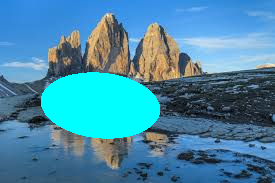

In [35]:
# disegnamo una ellisse PIENA colorando tutti i pixel
# --- con somma delle distanze dai fuochi <= D
from math import sqrt, dist

def draw_ellisse(img, x1, y1, x2, y2, D, colore):
    larghezza = len(img[0])
    altezza   = len(img)
    for x in range(larghezza):           # scandisco tutti i pixel della immagine
        for y in range(altezza):
            D1 = dist((x,y), (x1,y1))    # calcolo le due distanze dai fuochi
            D2 = dist((x,y), (x2,y2))
            if D1+D2 <= D:               # se la somma < D allora il pixel è DENTRO
                img[y][x] = colore       # lo coloro
                                         # altrimenti lo ignoro

# NOTA: non devo controllare se sono dentro l'immagine 
# perchè scandisco SOLO i pixel della immagine

# NOTA: D deve essere più grande della distanza tra i due fuochi
# TODO: si possono scandire meno pixel invece che tutta l'immagine
#       se capiamo in quale rettangolo cade l'ellisse (anche grossolanamente)

img = images.load('3cime.png')
draw_ellisse(img, 50, 100, 150, 110, 120,  cyan)

images.visd(img)

### Se vogliamo disegnare solo il bordo ?
- coloriamo solo i pixel che distano dai fuochi **circa** $D$
- ovvero **$|D1+D2-D|<1$**

NOTA: la differenza può essere ridotta a poco più di mezzo pixel

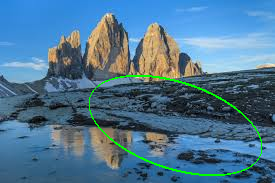

In [37]:
def draw_ellisse_vuota(img, x1, y1, x2, y2, D, colore):
    larghezza = len(img[0])
    altezza   = len(img)
    for x in range(larghezza):          # scandisco tutti i pixel della immagine
        for y in range(altezza):
            D1 = dist((x,y), (x1,y1))   # calcolo le due distanze dai fuochi
            D2 = dist((x,y), (x2,y2))
            if abs((D1+D2) - D) < 1 :   # se la somma - D è piccola sono sul bordo 
                img[y][x] = colore      # lo coloro
                                        # altrimenti lo ignoro

# D deve essere più grande della distanza tra i fuochi
img = images.load('3cime.png')
draw_ellisse_vuota(img, 100, 100, 250, 150, 180,  green)

images.visd(img)

## e per disegnare un cerchio? 
Un cerchio è una ellisse particolare
- ha i due fuochi nello stesso punto
- la somma delle distanze dai fuochi è quindi 2 volte il raggio

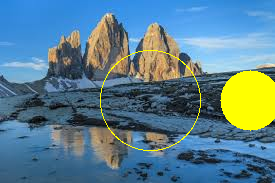

In [38]:
# cerchio = ellisse con entrambi i fuochi nello stesso punto e somma delle distanze = 2 raggio
def draw_circle(img, x, y, r, colore):
    draw_ellisse(img, x, y, x, y, 2*r, colore)

def draw_circle_vuoto(img, x, y, r, colore):
    draw_ellisse_vuota(img, x, y, x, y, 2*r, colore)

img = images.load('3cime.png')
draw_circle_vuoto(img, 150, 100, 50,  yellow)
draw_circle(img, 250, 100, 30,  yellow)

images.visd(img)

## Come disegnare una parabola? una iperbole? una funzione generica?
per esercizio, basta che vi ricordiate le funzioni e usiate draw_pixel

# ANALISI: Quesito con la Susi 965
![](Susi-965.jpeg)

## Idea di soluzione "brute force" (esplorando tutte le possibili soluzioni)
- trovo tutte le permutazioni delle 6 cifre (sono solo $6!=720$)
  - 6 possibilità per la prima cifra, per 5 per la seconda, per 4 per la terza ...
- per ciascuna permutazione calcolo i 5 prodotti richiesti
- e controllo che diano tutti come risultato un numero con quelle stesse cifre

Mi serve di:
- calcolare un numero data la sequenza di cifre
- calcolare i vari prodotti 
  - spezzare il risultato nelle sue cifre
  - controllare che due numeri contengano le stesse cifre

## per calcolare le permutazioni di 6 cifre
- per tutte le scelte della prima cifra A
  - per tutte le scelte della seconda cifra B (tra quelle rimaste)
    - per tutte le scelte della terza cifra C (tra quelle rimaste)
      - per tutte le scelte della quarta cifra D (tra quelle rimaste)
        - per tutte le scelte della quinta cifra E (tra quelle rimaste)
           - la sesta cifra F è unica
           - aggiungo la permutazione [A,B,C,D,E,F] al risultato
- ritorno l'elenco di permutazioni

**NOTA:** le cifre che ci interessano sono tutte diverse per cui possiamo usare gli insiemi

In [41]:
def permuta_6(cifre):
    cifre = set(cifre)                                   # trasformo in un insieme
    risultato = []
    for A in cifre:                                      # scelgo A
        for B in cifre - {A}:                            # scelgo B tra i rimanenti
            for C in cifre - {A,B}:                      # scelgo C tra i rimanenti
                for D in cifre - {A,B,C}:                # scelgo D tra i rimanenti
                    for E in cifre - {A,B,C,D}:          # scelgo E tra i rimanenti
                        F = (cifre - {A,B,C,D,E}).pop()  # F è l'unico rimasto
                        risultato.append([A,B,C,D,E,F])
    return risultato

cifre = [1, 2, 4, 5, 7, 8]
permutazioni = permuta_6(cifre)
print(len(permutazioni), permutazioni[:10])

720 [[1, 2, 8, 4, 5, 7], [1, 2, 8, 4, 7, 5], [1, 2, 8, 5, 4, 7], [1, 2, 8, 5, 7, 4], [1, 2, 8, 7, 4, 5], [1, 2, 8, 7, 5, 4], [1, 2, 4, 8, 5, 7], [1, 2, 4, 8, 7, 5], [1, 2, 4, 5, 8, 7], [1, 2, 4, 5, 7, 8]]


In [40]:
# oppure per ottenere le permutazioni sfrutto il modulo itertools, più generale
from itertools import permutations     # vedremo più in là come generarle noi
cifre = [1, 2, 4, 5, 7, 8]
permutazioni = list(permutations(cifre))  # torna una lista di tuple
print('Le permutazioni sono:', len(permutazioni),permutazioni[:10],sep='\n')

Le permutazioni sono:
720
[(1, 2, 4, 5, 7, 8), (1, 2, 4, 5, 8, 7), (1, 2, 4, 7, 5, 8), (1, 2, 4, 7, 8, 5), (1, 2, 4, 8, 5, 7), (1, 2, 4, 8, 7, 5), (1, 2, 5, 4, 7, 8), (1, 2, 5, 4, 8, 7), (1, 2, 5, 7, 4, 8), (1, 2, 5, 7, 8, 4)]


## Per convertire le cifre in numero
- posso passare per la stringa (ovvero cifre -> caratteri -> stringa -> numero)

In [43]:
Sequenza = list[int] | tuple[int,...]     # voglio usare tuple oppure liste
def calcola(cifre : Sequenza) -> int:
    'per convertire le cifre in numero passo per la stringa corrisponente'
    caratteri = [str(x) for x in cifre ]
    stringa   = ''.join(caratteri)
    return int(stringa)
    #return int(''.join(map(str,cifre))) # concateno e converto in intero

# oppure potrei calcolarlo direttamente con le potenze di dieci (a rovescio)
def calcola(cifre : Sequenza) -> int:
    return sum( cifra*10**esponente 
                for esponente,cifra in enumerate(reversed(cifre))) 

calcola((4, 7, 2, 5, 1))

47251

## Per convertire il numero in cifre
- posso passare per la stringa (ovvero numero -> stringa -> caratteri -> cifre)

In [44]:
def scomponi(numero : int) -> Sequenza:
    'per scomporre un numero nelle sue cifre passo per la stringa'
    stringa = str(numero)
    return [ int(carattere) for carattere in stringa ]
    #return list(map(int, str(numero)))  # converto tutto in stringa e poi in intero un carattere per volta

# Esempio
scomponi(123456)

[1, 2, 3, 4, 5, 6]

## per controllare che il prodotto per `X` dia un numero con le stesse cifre
- dalla permutazione ottengo il numero
- lo moltiplico per X
- riottengo le cifre
- controllo che siano le stesse (ad esempio confrontando le due liste di cifre ordinate)

In [45]:
def controlla(permutazione : Sequenza, X : int, verbose : bool=False) -> bool:
    'controllo che il prodotto della permutazione per X dia le stesse cifre'
    N = calcola(permutazione)                     # ottengo il numero
    cifre = scomponi(N*X)                         # moltiplico e scompongo
    if verbose: print(f"{N} x {X} = {N*X}")       # se voglio visualizzo il prodotto
    return sorted(cifre) == sorted(permutazione)  # verifico che siano le stesse cifre (i set non vanno bene)

# esempi presi dal quesito della Susi
controlla([1, 5, 3, 8, 4, 6], 3, True), controlla([1, 5, 3, 8, 4, 6], 4, True)

153846 x 3 = 461538
153846 x 4 = 615384


(True, True)

In [46]:
%%time
# e finalmente controlliamo tutte le permutazioni
for p in permutazioni:
    prodotti = [2, 3, 4, 5, 6]
    if all( controlla(p,X) for X in prodotti ):    # controllo tutti i prodotti
        for X in prodotti:                         # trovato
            controlla(p,X,True)                    # stampo il prodotto usando controlla

# la soluzione è unica!

142857 x 2 = 285714
142857 x 3 = 428571
142857 x 4 = 571428
142857 x 5 = 714285
142857 x 6 = 857142
CPU times: user 6.43 ms, sys: 499 μs, total: 6.93 ms
Wall time: 7.77 ms


## Potremmo dedurre alcune cose per restringere l'esplorazione (e rendere tutto più veloce)
Le cifre disponibili sono [1, 2, 4, 5, 7, 8]
- **A** deve essere **1** altrimenti **A*6** darebbe riporto
- 1BCDEF * 5 = un numero che finisce per 5 (se F dispari) o per 0 (se F pari)
  - 0 non è presente, **il risultato finisce per forza con 5**
  - e quindi **F deve essere dispari (e non può essere 1=A) quindi è 5 o 7**
- 1BCDEF * 6 = numero pari che finisce per (2,4,8) 
  - **MA non ammette F=1 o F=5 che darebbero come unità 0 oppure 6 che non sono presenti**
  - quindi **F=7**
- 1BCDE7 * 2 = numero che finisce per 4 OK
- 1BCDE7 * 4 = numero che finisce per 8 OK
- 1BCDE7 * 3 = numero che finisce per 1 OK

Quindi sappiamo che **F=7 e A=1** 
per cui possiamo rendere la ricerca più veloce 
esaminando solo le 24 permutazioni delle altre 4 cifre [4,2,8,5]

In [47]:
%%time 
for p in permutations([2,4,8,5]):   # permuto le sole cifre restanti
    #cifre = [1] + list(p) + [7]    # riottengo la lista di 6 cifre con concatenazioni
    cifre = [1, *p, 7]              # riottengo la lista di 6 cifre con unpacking
    prodotti = [2, 3, 4, 5, 6]
    if all( controlla(cifre,X) for X in prodotti ):   # continuo come prima
        for X in prodotti:
            controlla(cifre,X,True)

142857 x 2 = 285714
142857 x 3 = 428571
142857 x 4 = 571428
142857 x 5 = 714285
142857 x 6 = 857142
CPU times: user 201 μs, sys: 5 μs, total: 206 μs
Wall time: 204 μs
